In [1]:
import cobra
from cobra.io import read_sbml_model
from cobra.sampling import sample
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import pickle
import os
import itertools

# Simulations for O'Quinn et al. 2026 & Vailionis et al. 2026
* O’Quinn, Hailey, Jason Vailionis, Katherine Holandez-Lopez, Meghana Faltane, Tania N. N. Tanwee, Kathryne Ford, Farris L. Poole, Katherine B. Louie, Benjamin P. Bowen, Ying Zhang, Robert M. Kelly, and Michael W. W. Adam. 2026. "Engineering the Hyperthermophilic Archaeon Pyrococcus furiosus for 2,3-Butanediol Production Informed by Metabolic Modeling and Metabolomics". (Submitted to AEM)
* Vailionis, Jason L., Hailey C. O’Quinn, Katherine S. Holandez-Lopez, Meghana Faltane, Tania N. N. Tanwee, Kathryne C. Ford, Farris L. Poole, Katherine B. Louie, Benjamin P. Bowen, Robert M. Kelly, Michael W. W. Adams, and Ying Zhang. 2026. "Targeted and untargeted metabolomics with absolute quantification of intracellular metabolites in the hyperthermophilic archaeon Pyrococcus furiosus during 2,3-butanediol production". (Submitted to MRA)

## Model simulation helper functions

In [2]:
def create_rxn(model, name, cpd_dict, direction="both", limits=None):
    # Create a reaction from a dict with {"CPD1": -1, "CPD2: 1"}
    # Assuming the cpd ids are already in the model
    if direction not in ["forward", "reverse", "both"]:
        raise ValueError("Direction must be either forward, reverse, or both")
    rxn = cobra.Reaction(name)
    if limits is not None:
        if len(limits) != 2:
            raise ValueError("Limits must be of length 2")
        else:
            rxn.lower_bound = limits[0]
            rxn.upper_bound = limits[1]
    elif direction == "both":
        rxn.lower_bound = -1000
        rxn.upper_bound = 1000
    elif direction == "forward":
        rxn.lower_bound = 0
        rxn.upper_bound = 1000
    else:
        rxn.lower_bound = -1000
        rxn.upper_bound = 0
    rxn.add_metabolites({
        getattr(model.metabolites, cpd): val for cpd, val in cpd_dict.items()
    })
    print("Adding the following reaction to model:")
    print(rxn)
    model.add_reactions([rxn])

def plt_contributing_rxns(model, sample, cpd_id, n=10, scale=None):
    rxns = [x.id for x in getattr(model.metabolites, cpd_id).reactions]
    raw_means = sample[rxns].mean(axis=0)
    errors = sample[rxns].std(axis=0)
    for rxn in raw_means.index:
        direction = {cpd.id:val for cpd,val
                     in getattr(model.reactions, rxn).metabolites.items()}[cpd_id]
        raw_means[rxn] = raw_means[rxn]*direction
    topn = pd.concat([raw_means.sort_values(ascending=False).head(n),
                      raw_means.sort_values(ascending=False).tail(n)])
    print(raw_means[raw_means > 0].sum())
    if all(np.isnan(errors)):
        plt.bar(topn.index, topn)
    else:
        plt.bar(topn.index, topn, yerr=errors[topn.index])
    plt.xticks(rotation="vertical")
    if scale is not None:
        plt.yscale(scale)
    plt.tight_layout()
    plt.show()
    
def add_fixed_constraint(model, rxn, value):
    """
    model = cobra formatted model
    rxn = string of reaction id
    value = a single int/float to constrain the reaction to, or a list/tuple like (lb, ub)
    """
    try:
        lower = value[0]
        upper = value[1]
    except (TypeError, IndexError):
        lower = value
        upper = value
    constraint = model.problem.Constraint(
        getattr(model.reactions, rxn).flux_expression,
        lb=lower, ub=upper)
    model.add_cons_vars(constraint)
    return constraint

def plt_hist(*data, rxn=None, bins=20, labels=None, xlabel=None):
    # if rxn is not specified, it will treat the data as arrays
    # otherwise it will treat it as dataframes and subset rxn from them
    if labels is not None and len(data) != len(labels):
        raise ValueError("labels and data must be lists of same length")
    if labels is None:
        labels2 = [None]*len(data)
    else:
        labels2 = labels
    # parse data:
    if rxn is not None:
        arrays = [df[rxn] for df in data]
    else:
        arrays = data
    if type(bins) == int:
        binz = np.linspace(min(np.concatenate(arrays)),
                           max(np.concatenate(arrays)),
                           bins)
    elif len(bins) == 3:
        binz = np.linspace(bins[0], bins[1], bins[2])
    else:
        raise ValueError("Bins must be an integer (number of bins) or a " +
                         "list/tuple of length three; (min, max, nbins)")
    for arr,lab in zip(arrays,labels2):
        plt.hist(arr, bins=binz, label=lab, alpha=0.4, edgecolor="black")
    if labels is not None:
        plt.legend()
    if xlabel is None:
        plt.xlabel(rxn)
    else:
        plt.xlabel(xlabel)
    plt.show()




In [3]:
def get_stoichiometric_contribution(flux_sample, compound_id, model):
    """
    Adjusts the fluxes in your sample to represent the flux of a specific compound
    """
    # Create copy df with all zeros
    new_sample = pd.DataFrame().reindex_like(flux_sample).replace(np.nan, 0)
    for reaction in getattr(model.metabolites, compound_id).reactions:
        new_sample[reaction.id] = flux_sample[reaction.id] * reaction.get_coefficient(compound_id)
    return new_sample

def transform_to_scaled_proportion(row):
    total_flux = np.sum(np.abs(row))/2
    return row/total_flux

In [4]:
def get_phosphorylation_contribution(flux_sample, model):
    """
    Calculates the net phosphorylation state change for each reaction.
    Tracks all nucleotides (ATP, GTP, CTP, UTP, etc.) and free phosphates.
    
    Returns a DataFrame where each value represents the net high-energy 
    phosphate bonds produced (positive) or consumed (negative).
    """
    
    # Define phosphorylation states
    # These are common KEGG/BiGG IDs - adjust for your model
    nucleotide_triphosphates = {
        'C00002': 'atp',    # ATP
        'C00044': 'gtp',    # GTP  
        'C00063': 'ctp',    # CTP
        'C00075': 'utp',    # UTP
        'C00081': 'itp',    # ITP
        'C00131': 'dttp',   # dTTP
        'C00286': 'datp',   # dATP
        'C00459': 'dgtp',   # dGTP
        'C00458': 'dctp',   # dCTP
        'C01345': 'ditp',   # dITP
    }
    
    nucleotide_diphosphates = {
        'C00008': 'adp',    # ADP
        'C00035': 'gdp',    # GDP
        'C00112': 'cdp',    # CDP
        'C00015': 'udp',    # UDP
        'C00104': 'idp',    # IDP
        'C00206': 'dtdp',   # dTDP
        'C00206': 'dadp',   # dADP
        'C00361': 'dgdp',   # dGDP
        'C00705': 'dcdp',   # dCDP
        'C01344': 'didp',   # dIDP
    }
    
    nucleotide_monophosphates = {
        'C00020': 'amp',    # AMP
        'C00144': 'gmp',    # GMP
        'C00055': 'cmp',    # CMP
        'C00105': 'ump',    # UMP
        'C00130': 'imp',    # IMP
        'C00364': 'dtmp',   # dTMP
        'C00413': 'damp',   # dAMP
        'C00362': 'dgmp',   # dGMP
        'C01081': 'dcmp',   # dCMP
        'C06196': 'dimp',   # dIMP
    }
    
    phosphates = {
        'C00009': 'pi',     # Phosphate (Pi)
        'C00013': 'ppi',    # Pyrophosphate (PPi)
    }
    
    # Assign phosphorylation values
    phosphate_values = {}
    for cpd_id in nucleotide_triphosphates.keys():
        phosphate_values[cpd_id] = 2  # 2 high-energy bonds
    for cpd_id in nucleotide_diphosphates.keys():
        phosphate_values[cpd_id] = 1  # 1 high-energy bond
    for cpd_id in nucleotide_monophosphates.keys():
        phosphate_values[cpd_id] = 0  # 0 high-energy bonds
    phosphate_values['C00009'] = 0   # Pi - no high-energy bond
    phosphate_values['C00013'] = 1   # PPi - 1 high-energy bond
    
    # Calculate net phosphorylation for each reaction
    new_sample = pd.DataFrame().reindex_like(flux_sample).replace(np.nan, 0)
    
    for reaction in model.reactions:
        # Calculate net phosphorylation state change
        net_phosphorylation = 0
        
        for metabolite, coefficient in reaction.metabolites.items():
            met_id = metabolite.id
            
            # Check if this metabolite contributes to phosphorylation state
            if met_id in phosphate_values:
                # Positive coefficient = product (increases if value is positive)
                # Negative coefficient = reactant (decreases if value is positive)
                net_phosphorylation += coefficient * phosphate_values[met_id]
        
        # Multiply by flux to get contribution
        new_sample[reaction.id] = flux_sample[reaction.id] * net_phosphorylation
    
    return new_sample

## Loading model and constraining the experimental data

In [5]:
cobra_model = read_sbml_model("../../sbmls/5564dbe3_bdo_cellobiose.sbml")
constraint_data = pd.read_table("./data/2026-03-03_PFU_BDO_carbon_closure.tsv")
outdir = "./output"

'' is not a valid SBML 'SId'.


In [6]:
# Create a model for each strain
# Constrain the data to be mean +/- stderr
models = {strain: cobra_model.copy()
          for strain in constraint_data["strain"].unique()}

for _, row in constraint_data.iterrows():
    # Skip constraining CO2; this is calculated from other products anyways
    if row["id_cobra"] == "TP_CO2":
        continue
    reaction = getattr(models[row["strain"]].reactions, row["id_cobra"])
    reaction.bounds = (row["lb"], row["ub"])

Verifying that the models are feasible under the constraints

In [7]:
for strain, model in models.items():
    try:
        model.optimize()
        cobra.util.assert_optimal(model)
    except (cobra.exceptions.Infeasible, cobra.exceptions.OptimizationError) as e:
        print(f"{strain} failed: {e}")
    else:
        print(f"{strain} passed")

MW698 passed
MW697 passed
MW268 passed
COM1c passed


# Flux sampling

### Only run this if you want to compute new samples

In [9]:
# Random sampling of all the models
samples = {
    strain: sample(model, 5000, processes=4)
    for strain, model in models.items()
}

In [61]:
with open(os.path.join(outdir, "samples_dict.pkl"), 'wb') as f:
    pickle.dump(samples, f)

### Read in the precomputed samples

In [8]:
with open(os.path.join(outdir, "samples_dict.pkl"), 'rb') as f:
    samples = pickle.load(f)

In [9]:
samples_c_adjusted = {
    strain: df.div(-df["EX_C00185_LSQBKT_e_RSQBKT_"], axis=0)
    for strain, df in samples.items()
}

In [10]:
samples_bio_adjusted = {
    strain: df.div(df["Biomass_Pfu"], axis=0)
    for strain, df in samples.items()
}

In [11]:
# Convert from dictionary to pd df
tmp_data = []
for strain, df in samples_c_adjusted.items():
    df2 = df.copy()
    df2["strain"] = strain
    tmp_data.append(df2)

samples_c_adjusted_df = pd.concat(tmp_data)

In [12]:
# Convert from dictionary to pd df
tmp_data = []
for strain, df in samples.items():
    df2 = df.copy()
    df2["strain"] = strain
    tmp_data.append(df2)

samples_df = pd.concat(tmp_data)

# Figure 8: Redox contributions across the model

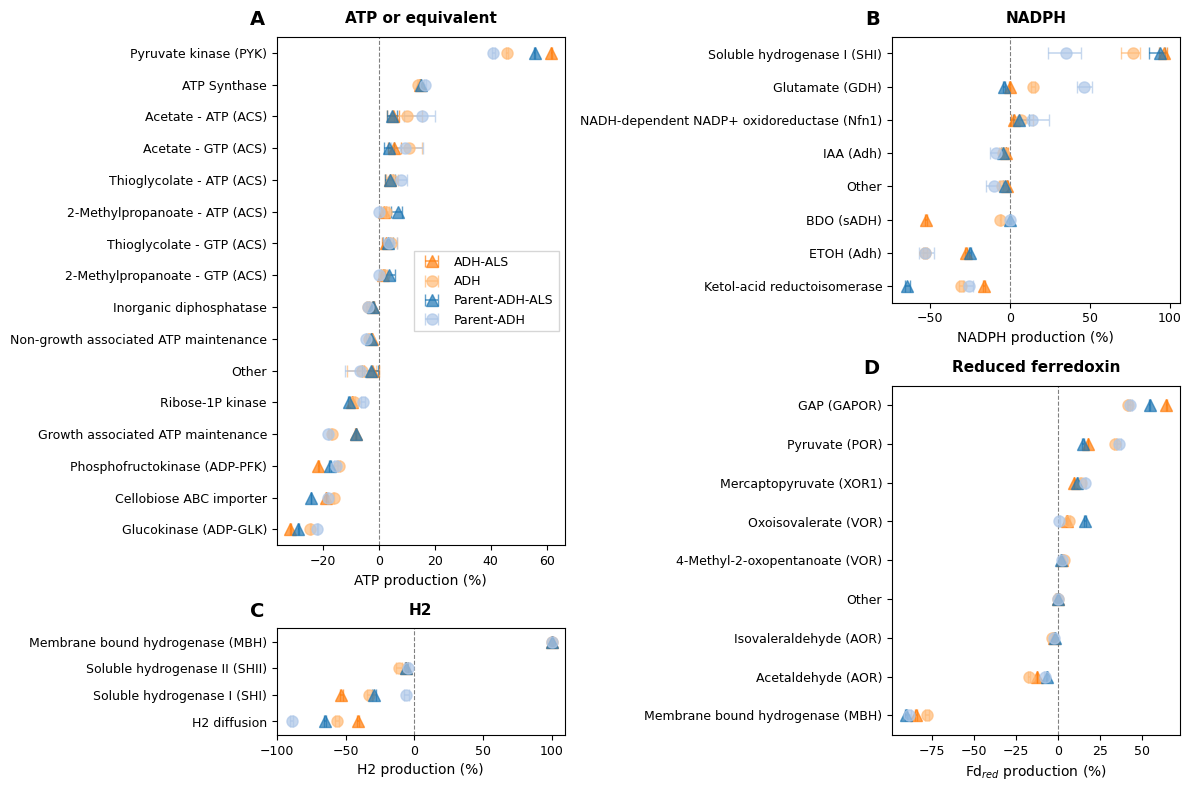

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import os

# Define configurations for each panel with manual labels
panel_configs = {
    'A': {'target_id': 'Phosphorylation', 'threshold': 3, 'use_percentage': True,
          'title': 'ATP or equivalent', 'xlabel': 'ATP production (%)'},
    'C': {'target_id': 'C00282', 'threshold': 0.0, 'use_percentage': True,
          'title': 'H2', 'xlabel': 'H2 production (%)'},
    'D': {'target_id': 'C00138', 'threshold': 3, 'use_percentage': True,
          'title': 'Reduced ferredoxin', 'xlabel': 'Fd$_{red}$ production (%)'},
    'B': {'target_id': 'C00005', 'threshold': 3, 'use_percentage': True,
          'title': 'NADPH', 'xlabel': 'NADPH production (%)'},
}

# Define layout using subplot_mosaic syntax
layout = [
    ['A', 'B'],
    ['A', 'D'],
    ['C', 'D'],
]
width_ratios = [1, 1]
height_ratios = [0.5, 0.3, 0.2]
figsize = (12, 8)

# Reaction name mapping
reaction_map = {
    "R07181": "Soluble hydrogenase I (SHI)", "TP_H2": "H2 diffusion",
    "R00700": "Soluble hydrogenase II (SHII)", "mbh": "Membrane bound hydrogenase (MBH)",
    "R07159": "GAP (GAPOR)", "R01196": "Pyruvate (POR)",
    "R07160_H": "Oxoisovalerate (VOR)", "xor1": "Mercaptopyruvate (XOR1)",
    "R08566_H": "4-Methyl-2-oxopentanoate (VOR)", "R01197": "α-ketoglutarate (OGOR)",
    "nfn1": "NADH-dependent NADP+ oxidoreductase (Nfn1)", "AOR_Isovaleraldehyde": "Isovaleraldehyde (AOR)",
    "AOR_acetaldehyde": "Acetaldehyde (AOR)",
    "R00248": "Glutamate (GDH)", "Adh_iaa_nadp": "IAA (Adh)",
    "R00746": "ETOH (Adh)", "R04440": "Ketol-acid reductoisomerase",
    "R02946_Tg_sADH": "BDO (sADH)",
    "R00200": "Pyruvate kinase (PYK)", "atps": "ATP Synthase",
    "R00229": "Acetate - ATP (ACS)", "acs3G": "2-Methylpropanoate - GTP (ACS)",
    "R00229_DASH_G": "Acetate - GTP (ACS)", "acs9": "Thioglycolate - ATP (ACS)",
    "acs3": "2-Methylpropanoate - ATP (ACS)", "acs9G": "Thioglycolate - GTP (ACS)",
    "acs4G": "Isovalerate - GTP (ACS)", "NGAM": "Non-growth associated ATP maintenance",
    "GAM_biomass": "Growth associated ATP maintenance", "R11535": "Ribose-1P kinase",
    "R05805": "Phosphofructokinase (ADP-PFK)", "cellobioseABC": "Cellobiose ABC importer",
    "R05804": "Glucokinase (ADP-GLK)",
    "R00004": "Inorganic diphosphatase"
}

# Aesthetic mappings
colors = sns.color_palette("tab20", n_colors=4)
bdo_colors = {'MW698': colors[2], 'MW697': colors[3]}
non_bdo_colors = {'MW268': colors[0], 'COM1c': colors[1]}
color_map = {**bdo_colors, **non_bdo_colors}

marker_map = {'MW698': '^', 'MW697': 'o', 'MW268': '^', 'COM1c': 'o'}
label_map = {'MW698': 'ADH-ALS', 'MW697': 'ADH', 'MW268': 'Parent-ADH-ALS', 'COM1c': 'Parent-ADH'}


def process_panel_data(target_id, threshold, use_percentage):
    """Process data for a single panel, returning median, Q1, Q3 per reaction per strain."""
    
    median_data = []
    q1_data = []
    q3_data = []

    for strain in samples.keys():
        if target_id == "Phosphorylation":
            df_mM_cpd = get_phosphorylation_contribution(
                samples[strain], models[strain]
            )
        else:
            df_mM_cpd = get_stoichiometric_contribution(
                samples[strain], target_id, models[strain]
            )

        if use_percentage:
            df_mM_cpd = 100*df_mM_cpd.apply(transform_to_scaled_proportion, axis=1)

        # Compute median, Q1, Q3 across samples (rows = samples, cols = reactions)
        median_series = df_mM_cpd.median().replace(0, np.nan).dropna()
        q1_series   = df_mM_cpd.quantile(0.25).reindex(median_series.index)
        q3_series   = df_mM_cpd.quantile(0.75).reindex(median_series.index)

        median_series.name = strain
        q1_series.name   = strain
        q3_series.name   = strain

        median_data.append(median_series)
        q1_data.append(q1_series)
        q3_data.append(q3_series)

    median_df = pd.concat(median_data, axis=1)
    q1_df   = pd.concat(q1_data,   axis=1)
    q3_df   = pd.concat(q3_data,   axis=1)

    # Filter by threshold (based on median)
    mask_below = (median_df.abs() <= threshold).all(axis=1)
    
    def aggregate(df):
        major = df[~mask_below].copy()
        minor = df[mask_below].copy()
        other_row = minor.sum(axis=0).to_frame().T
        other_row.index = ['Other']
        if not (other_row == 0).all().all():
            return pd.concat([major, other_row]).replace(np.nan, 0)
        return major.replace(np.nan, 0)

    combined_median = aggregate(median_df)
    combined_q1   = aggregate(q1_df)
    combined_q3   = aggregate(q3_df)

    # Sort rows by extreme value of median
    def get_extreme_value(row):
        abs_vals = row.abs()
        max_idx = abs_vals.idxmax()
        return row[max_idx]

    extreme_values = combined_median.apply(get_extreme_value, axis=1)
    sort_order = extreme_values.sort_values(ascending=True).index

    combined_median = combined_median.loc[sort_order]
    combined_q1   = combined_q1.loc[sort_order]
    combined_q3   = combined_q3.loc[sort_order]

    # Melt each to long format and merge
    def melt_df(df, value_name):
        melted = df.reset_index().melt(id_vars="index", value_name=value_name)
        melted['label'] = melted['index'].map(reaction_map).fillna(melted['index'])
        return melted

    plot_median = melt_df(combined_median, 'value')
    plot_q1   = melt_df(combined_q1,   'q1')
    plot_q3   = melt_df(combined_q3,   'q3')

    # Merge into a single dataframe
    plot_df = plot_median.copy()
    plot_df['q1'] = plot_q1['q1'].values
    plot_df['q3'] = plot_q3['q3'].values

    return plot_df, combined_median


# Create figure
fig, axs = plt.subplot_mosaic(layout, width_ratios=width_ratios,
                              height_ratios=height_ratios, figsize=figsize)

first_panel = True
save_it = []
for panel_label, config in panel_configs.items():
    if panel_label not in axs:
        continue

    ax = axs[panel_label]

    plot_df, combined_df = process_panel_data(
        config['target_id'], config['threshold'], config['use_percentage']
    )
    save_it.append([plot_df, combined_df])

    if config['target_id'] == "Phosphorylation":
        label = "Phosphorylation"
    else:
        label = getattr(cobra_model.metabolites, config['target_id']).name

    # Plot each strain with IQR error bars
    for strain in ['MW698', 'MW697', 'MW268', 'COM1c']:
        strain_data = plot_df[plot_df['variable'] == strain].copy()

        # Compute asymmetric error bars: distance from median to Q1 and Q3
        xerr_low  = (strain_data['value'] - strain_data['q1']).clip(lower=0).values
        xerr_high = (strain_data['q3'] - strain_data['value']).clip(lower=0).values

        ax.errorbar(
            x=strain_data['value'],
            y=strain_data['label'],
            xerr=[xerr_low, xerr_high],
            fmt=marker_map[strain],        # marker style
            color=color_map[strain],
            markersize=8,
            alpha=0.7,
            capsize=4,                     # width of the error bar caps
            capthick=1.0,
            elinewidth=1.2,
            label=label_map[strain] if first_panel else "",
        )

    n_reactions = len(plot_df['label'].unique())
    fixed_margin = 0.5
    ax.set_ylim(-fixed_margin, n_reactions - 1 + fixed_margin)

    ax.axvline(0, color="grey", ls="--", zorder=0, linewidth=0.8)

    if 'xlabel' in config:
        ax.set_xlabel(config['xlabel'])
    elif config['use_percentage']:
        ax.set_xlabel(f'{label} flux (%)', fontsize=10)
    else:
        ax.set_xlabel(f'{label} flux (mM)', fontsize=10)

    ax.set_ylabel('', fontsize=10)
    
    if 'title' in config:
        ax.set_title(config['title'], fontsize=11, pad=10, fontweight='bold')
    ax.tick_params(axis='both', labelsize=9)

    if first_panel:
        ax.legend(loc='center right', fontsize=9, frameon=True, fancybox=False)
        first_panel = False

plt.tight_layout()

# Add panel labels
for panel_label, config in panel_configs.items():
    if panel_label not in axs:
        continue
    ax = axs[panel_label]

    # Get the bounding box of the axes in figure coordinates
    bb = ax.get_position()  # returns Bbox with x0, y0, x1, y1 in figure fraction

    # Place label at top-left of axes, with a small offset
    x_fig = bb.x0 - 0.01   # nudge left
    y_fig = bb.y1 + 0.01   # nudge above top edge

    fig.text(
        x_fig, y_fig,
        panel_label,
        fontsize=14,
        fontweight='bold',
        va='bottom',   # anchor bottom of text to the y coordinate
        ha='right',
        transform=fig.transFigure
    )

plt.savefig(os.path.join(outdir, 'Fig_8_energy_balance.png'),
            dpi=300, bbox_inches='tight')
plt.show()

In [14]:
# extracting the data to get values for the paper
# Change the first index to cycle between the panels
save_it[3][1]

,MW698,MW697,MW268,COM1c
R04440,-15.865977,-30.540942,-63.835848,-25.364907
R00746,-27.209724,-52.828770,-24.649617,-52.720862
R02946_Tg_sADH,-52.283999,-5.832616,0.000000,0.000000
Other,-1.628266,-4.503595,-2.945005,-9.521920
Adh_iaa_nadp,-2.111685,-4.282548,-3.855168,-8.278210
nfn1,2.890310,7.302197,5.604365,13.800132
R00248,0.014607,14.452192,-3.474915,46.254276
R07181,96.466982,77.246593,93.606387,35.453840


In [15]:
# Example extracting raw flux data to calculate fold changes
table_a = samples_df.groupby("strain")[["Biomass_Pfu", "GAM_biomass", "R05804", "R00200",
                                         "mbh", "R07181", "R00248", "R01196", "R00226", "R00229", "R00229_DASH_G", "atps",
                                         "nfn1", "R00248", "TP_H2"]].median().T
table_a.index = ["Biomass", "Growth-associated ATP",
                 "Glucokinase", "Pyruvate kinase", "Membrane bound hydrogenase",
                 "Soluble hydrogenase I", "Glutamate dehydrogenase", "Pyruvate ferredoxin oxidoreductase",
                 "Acetolactate synthase", "ACS", "ACS-G", "ATPSYN", "nfn1", "GDH", "H2 diffusion"]
table_a.columns = ["Parent-ADH", "Parent-ADH-ALS", "ADH", "ADH-ALS"]
table_a["units"] = "mM"
table_a.loc["Biomass", "units"] = "g/L"

table_a.round(4)

,Parent-ADH,Parent-ADH-ALS,ADH,ADH-ALS,units
Biomass,0.1262,0.0914,0.1460,0.1040,g/L
Growth-associated ATP,9.4341,6.8281,10.9138,7.7729,mM
Glucokinase,11.5655,24.3214,15.9164,29.9992,mM
Pyruvate kinase,21.5576,47.2372,29.7682,58.4075,mM
Membrane bound hydrogenase,33.6524,48.8590,34.9723,53.6117,mM
Soluble hydrogenase I,1.9716,14.3579,11.4970,28.6868,mM
Glutamate dehydrogenase,2.6325,-0.5348,2.1643,0.0043,mM
Pyruvate ferredoxin oxidoreductase,13.7871,8.0606,15.1904,11.3414,mM
Acetolactate synthase,2.1594,16.1678,5.4748,20.4849,mM
ACS,8.1303,4.1321,6.5943,4.9273,mM


In [16]:
round(np.log2(table_a.loc["GDH", "ADH"]/table_a.loc["GDH", "Parent-ADH"]), 2)

-0.28

# Figure 9: Metabolomics differential abundance analysis results

The DEA analysis (limma) was performed in the other notebook (`metabolomics_DEA.ipynb`). 

Here we read in those results and plot them

In [17]:
limma_results_dir = "./data/metabolomics"
pfu_targeted_limma = pd.read_table(os.path.join(limma_results_dir, "2026-04-05_Pfu_targeted_limma_results.csv"), sep=",", index_col=0)
pfu_untargeted_limma = pd.read_table(os.path.join(limma_results_dir, "2026-04-05_Pfu_untargeted_limma_results.csv"), sep=",", index_col=0)

In [18]:
# Drop replicate data caused by re-analysis of the original targeted data
pfu_targeted_limma = pfu_targeted_limma.drop_duplicates(["logFC", "AveExpr", "t"]).reset_index(drop=True)

### Mapping metabolomics data to metabolites in the model

**You can skip this section and read the mapped data below**

To map the data, we attempt to find a structural representation of each molecule (inchi string). Then we perform molecular fingerprinting and detect the ones with perfect matches.

In [34]:
metabName_to_inchi_mapping = pd.read_table("./data/metab_pubchem_map.tsv")
modelId_to_inchi_mapping = pd.read_table("./data/pfu_inchi_database.tsv")

In [35]:
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
import time
from tqdm import tqdm
import numpy as np

def compute_fingerprints(df, inchi_col='inchi', name_col=None):
    """
    Compute molecular fingerprints from InChI strings
    
    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame with InChI strings
    inchi_col : str
        Name of column containing InChI strings
    name_col : str
        Name of column with identifiers (optional)
    
    Returns:
    --------
    pd.DataFrame with columns: name, inchi, mol, fingerprint (only valid mols)
    """
    print(f"Computing fingerprints for {len(df)} molecules...")
    
    working_df = df.copy()
    
    # Convert InChI to molecules
    print("Converting InChI to molecules...")
    working_df['mol'] = [Chem.MolFromInchi(inchi) if pd.notna(inchi) else None 
                         for inchi in tqdm(working_df[inchi_col])]
    
    # Drop molecules that failed to convert
    n_before = len(working_df)
    working_df = working_df.dropna(subset=['mol'])
    n_after = len(working_df)
    if n_before > n_after:
        print(f"Warning: {n_before - n_after} molecules failed to convert from InChI")
    
    # Generate fingerprints
    print("Generating fingerprints...")
    fpgen = AllChem.GetRDKitFPGenerator()
    working_df['fingerprint'] = [fpgen.GetFingerprint(mol) 
                                  for mol in tqdm(working_df['mol'])]
    
    # Select relevant columns
    cols_to_keep = [inchi_col, 'mol', 'fingerprint']
    if name_col and name_col in working_df.columns:
        cols_to_keep.insert(0, name_col)
    
    return working_df


def find_best_matches(query_df, reference_df, 
                     query_name_col='query_name',
                     ref_name_col='label',
                     top_n=5,
                     similarity_threshold=0.0):
    """
    Find best structural matches between query and reference databases
    
    Parameters:
    -----------
    query_df : pd.DataFrame
        Query dataframe with 'fingerprint' column
    reference_df : pd.DataFrame
        Reference dataframe with 'fingerprint' column
    query_name_col : str
        Column name for query identifiers
    ref_name_col : str
        Column name for reference identifiers
    top_n : int
        Number of top matches to keep per query
    similarity_threshold : float
        Minimum Tanimoto similarity to include (0-1)
    
    Returns:
    --------
    pd.DataFrame with columns: query_name, ref_name, tanimoto_similarity
    """
    print(f"\nComputing Tanimoto similarities...")
    print(f"Query metabolites: {len(query_df)}")
    print(f"Reference metabolites: {len(reference_df)}")
    print(f"Total comparisons: {len(query_df) * len(reference_df):,}")
    
    all_matches = []
    
    t0 = time.time()
    
    for i, query_row in tqdm(query_df.iterrows(), total=len(query_df), desc="Comparing"):
        query_fp = query_row['fingerprint']
        query_name = query_row.get(query_name_col, f"Query_{i}")
        
        # Compute similarities to all reference metabolites
        match_data = []
        for j, ref_row in reference_df.iterrows():
            ref_fp = ref_row['fingerprint']
            ref_name = ref_row.get(ref_name_col, f"Ref_{j}")
            
            similarity = DataStructs.TanimotoSimilarity(query_fp, ref_fp)
            
            if similarity >= similarity_threshold:
                match_data.append({
                    'query_name': query_name,
                    'ref_name': ref_name,
                    'tanimoto_similarity': similarity
                })
        
        # Sort by similarity and keep top N
        if match_data:
            match_df = pd.DataFrame(match_data)
            match_df = match_df.sort_values('tanimoto_similarity', ascending=False).head(top_n)
            all_matches.append(match_df)
    
    t1 = time.time()
    print(f"Took {round(t1-t0, 2)} seconds")
    
    # Combine all matches
    if all_matches:
        result_df = pd.concat(all_matches, ignore_index=True)
        return result_df
    else:
        return pd.DataFrame(columns=['query_name', 'ref_name', 'tanimoto_similarity'])


def get_perfect_matches(similarity_df, threshold=1.0):
    """Extract perfect or near-perfect matches"""
    return similarity_df[similarity_df['tanimoto_similarity'] >= threshold]


def main_structure_matching(query_df, reference_df, 
                           query_inchi_col='inchi',
                           ref_inchi_col='inchi',
                           query_name_col='query_name',
                           ref_name_col='label',
                           top_n=5,
                           similarity_threshold=0.5):
    """
    Complete pipeline for structure matching
    """
    print("="*60)
    print("STRUCTURE MATCHING PIPELINE")
    print("="*60)
    
    # Step 1: Prepare query database (PubChem results)
    print("\n[1/3] Preparing query database (PubChem results)...")
    # Only use rows where we found something
    query_with_structure = query_df[query_df['inchi'].notna()].copy()
    print(f"Queries with valid InChI: {len(query_with_structure)}")
    
    query_fp_df = compute_fingerprints(
        query_with_structure, 
        inchi_col=query_inchi_col,
        name_col=query_name_col
    )
    
    # Step 2: Prepare reference database (internal model)
    print(f"\n[2/3] Preparing reference database (reference_df)...")
    ref_with_structure = reference_df[reference_df[ref_inchi_col].notna()].copy()
    print(f"References with valid InChI: {len(ref_with_structure)}")
    
    ref_fp_df = compute_fingerprints(
        ref_with_structure,
        inchi_col=ref_inchi_col,
        name_col=ref_name_col
    )
    
    # Step 3: Find matches
    print(f"\n[3/3] Finding structural matches...")
    similarity_df = find_best_matches(
        query_fp_df,
        ref_fp_df,
        query_name_col=query_name_col,
        ref_name_col=ref_name_col,
        top_n=top_n,
        similarity_threshold=similarity_threshold
    )
    
    return similarity_df, query_fp_df, ref_fp_df

In [36]:
similarity_results, query_fps, ref_fps = main_structure_matching(
    query_df=metabName_to_inchi_mapping,
    reference_df=modelId_to_inchi_mapping,
    query_inchi_col='inchi',
    ref_inchi_col='inchi',
    query_name_col='metabolite_name',
    ref_name_col='name',
    top_n=5,
    similarity_threshold=0.5
)

STRUCTURE MATCHING PIPELINE

[1/3] Preparing query database (PubChem results)...
Queries with valid InChI: 477
Computing fingerprints for 477 molecules...
Converting InChI to molecules...


100%|██████████| 477/477 [00:00<00:00, 1108.61it/s]


Generating fingerprints...


100%|██████████| 477/477 [00:00<00:00, 2725.14it/s]



[2/3] Preparing reference database (reference_df)...
References with valid InChI: 782
Computing fingerprints for 782 molecules...
Converting InChI to molecules...


  0%|          | 0/782 [00:00<?, ?it/s][15:41:06] WARNING:  Problems/mismatches: Mobile-H( Proton balance: Does not match)

[15:41:06] WARNING:  Problems/mismatches: Mobile-H( Proton balance: Does not match)

[15:41:06] WARNING: not removing hydrogen atom without neighbors
[15:41:06] WARNING: not removing hydrogen atom without neighbors
100%|██████████| 782/782 [00:00<00:00, 1961.45it/s]


Generating fingerprints...


100%|██████████| 782/782 [00:00<00:00, 1451.48it/s]



[3/3] Finding structural matches...

Computing Tanimoto similarities...
Query metabolites: 477
Reference metabolites: 782
Total comparisons: 373,014


Comparing: 100%|██████████| 477/477 [00:10<00:00, 46.54it/s]

Took 10.25 seconds


Text(0.5, 0, 'Tanimonto similarity score')

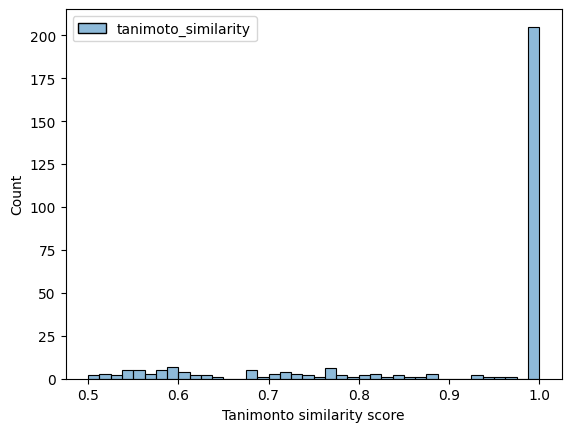

In [37]:
# Histogram of similarity scores
# The high peak at 1 indicates that we can clearly separate matches from non-matches
sns.histplot(similarity_results.groupby("query_name").max("tanimoto_similarity"),
             bins=40)
plt.xlabel("Tanimonto similarity score")

Overview of the tables and their identifying keys:
1. `modelId_to_inchi_mapping`
    * id: psamm model ID
    * name: psamm model name
2. `metabName_to_inchi_mapping`
    * metabolite_name: JGI internal name (or name from automatic annotation for untargeted)
    * query_name: Cleaned version of the JGI internal name, used to query pubchem
3. `similarity_results`
    * **The columns for this depend on which ones you chose when calling the main_structure_matching function**.
    Based on this structure: `query_name_col='metabolite_name', ref_name_col='name'` the columns would be the following:  
    * `query_name`: `metabolite_name` from `metabName_to_inchi_mapping`
    * `ref_name`: `name` from `modelId_to_inchi_mapping`
4. `pfu_targeted_limma`:
    * `metabolite`: JGI internal name.  
    Corresponds to `metabolite_name` from `metabName_to_inchi_mapping`
5. `pfu_untargeted_limma`:
    * `propagated_annotation`: Automatic name from untargeted annotation.
    Corresponds to `metabolite_name` from `metabName_to_inchi_mapping`
    

Mapping procedure:

0. Filter similarity_results to only include perfect matches
1. Merge similarity_results with modelId_to_inchi_mapping, mapping 'ref_name' to 'name'. Drop the inchi columns
2. Merge pfu_targeted_limma with table from 1, mapping 'metabolite' to 'query_name'
3. Merge pfu_untargeted_limma with table from 1, mapping 'propagated_annotation' to 'query_name'

In [38]:
perfect_matches = similarity_results.query("tanimoto_similarity > 0.999")

In [39]:
model_to_JGI_map = (modelId_to_inchi_mapping
    .merge(perfect_matches, left_on="name", right_on="ref_name")
    .drop(columns=["name", "inchi", "inchi_key", "neutral_inchi",
                   "neutral_inchi_key", "tanimoto_similarity"])
    .rename(columns={"query_name": "JGI_name", "ref_name": "model_name",
                     "id": "model_id"})
                    )

In [41]:
# Save the data to a tsv
model_to_JGI_map.drop_duplicates(["JGI_name"]).to_csv(
    os.path.join(outdir, "model_to_JGI_map.tsv"), sep="\t")

Next, I manually curated some of the IDs (particularly important for sugars). 
For some sugars, metabolomics won't be able to distinguish them (e.g. mannose vs glucose). I chose the version that we expect to see in the model (e.g. mannose in the metabolomics data maps to glucose in the model).

The edited version is saved in `model_to_JGI_map_edited.tsv`

### Read in the model mapping results

In [19]:
# After editing the table manually, reread it
model_to_JGI_map = pd.read_table(os.path.join(outdir, "model_to_JGI_map_edited.tsv"),
                                 sep="\t", index_col=0)

In [20]:
# Priority is used to weight higher quality annotations first
targ_annot = pfu_targeted_limma.merge(model_to_JGI_map, left_on="metabolite", right_on="JGI_name")
targ_annot["priority"] = 0

untarg_annot = pfu_untargeted_limma.merge(model_to_JGI_map, left_on="propagated_annotation", right_on="JGI_name")
untarg_annot["priority"] = 1
untarg_annot.loc[untarg_annot["annotation_source"] == "propagated", "priority"] = 2

In [21]:
# Merging targeted and untargeted annotations
limma_results = pd.concat([targ_annot, untarg_annot]).drop(columns=[
    "fullpath", "feature_id", "metabolite", "adduct", "row.m.z",
    "row.retention.time", "propagated_annotation"])

limma_results_dedupe = (limma_results
                        .sort_values(["priority", "adj.P.Val"])
                        .drop_duplicates("model_id", keep="first"))

In [22]:
limma_results_dedupe.to_csv(os.path.join(outdir, "limma_results_dedupe.tsv"), sep="\t")

### Plotting

In [23]:
pathway_classification = {
    'Glycolysis/Central Carbon': [
        'Phosphoenolpyruvate (PEP)',
        '3-Phospho-D-glycerate (3PG)',
        '2-Phospho-D-glycerate (2PG)',
        'Glyceraldehyde 3-phosphate (GAP)',
        'D-Glucose 6-phosphate (G6P)',
        'D-Fructose 6-phosphate (F6P)',
        'Pyruvate (Pyr)',
        'D-Glucose',
        'Acetyl-CoA (AcCoA)',
        'Isocitrate',
        'Fumarate',
        'L-Malate',
        'Acetoin'
    ],
    
    'Purine Metabolism': [
        'Guanine',
        'Hypoxanthine',
        'Adenine',
        'AMP',
        'Adenosine',
        'Inosine',
        'Guanosine',
        'ADP',
        'dAMP'
    ],
    
    'Pyrimidine Metabolism': [
        'Cytosine',
        'Uracil',
        'Cytidine',
        'Thymine',
        'Deoxycytidine',
        'Thymidine',
        'Uridine',
        'Orotate'
    ],
    
    'NAD/Nicotinamide': [
        'NADP',
        'NAD',
        'Nicotinamide'
    ],
    
    'Vitamins': [
        'Thiamine',
        'Riboflavin',
        'Biotin',
        'Pantothenate',
        'Pyridoxine'
    ],
    
    'Polyamines and SAM-related': [
        'L-2-Aminoadipate',
        'Putrescine',
        'Spermine',
        'Agmatine',
        'L-Citrulline (Clt)',
        'L-Lysine (lys-L)',
        'L-Proline (Pro-L)',
        'L-Arginine (Arg-L)',
        'L-Methionine (Met-L)',
        'L-Ornithine (Orn)',
        '5-Methylthioadenosine',
        'S-Adenosyl-L-methionine (SAM)'
    ],
    
    'Lipid Precursors': [
        '(R)-Mevalonate (MEV)',
        'myo-Inositol',
    ],
    
    'Branched-Chain Amino Acids': [
        'L-Isoleucine (Ile-L)',
        'L-Leucine (Leu-L)',
        '4-Methyl-2-oxopentanoate',
        'Citraconic acid'
    ],
    
    'Aromatic Amino Acids': [
        'L-Phenylalanine (Phe-L)',
        'L-Tyrosine (Tyr-L)',
        'L-Tryptophan (Trp-L)',
        'Anthranilate',
        'Indole-3-acetate',
    ],
    
    'Other Amino Acids': [
        'L-Aspartic acid (Asp-L)',
        'L-Histidine (His-L)',
        'L-Glutamine (Gln-L)',
        'L-Glutamic acid (Glu-L)',
        'L-Alanine (Ala-L)',
        'L-Homoserine',
        'L-Serine (Ser-L)',
        'L-Asparagine (Asn-L)',
        'L-Glycine (Gly-L)',
        'L-Threonine (Thr-L)',
    ],
    
    'Sugars & Carbohydrates': [
        'Mannitol',
        'Gentiobiose',
        'alpha,alpha-Trehalose',
        'Maltose',
        'Raffinose',
        'Cellobiose',
        'Sucrose',
        'D-Mannose',
        'D-Gluconate'
    ],
    
    'Amino Sugars & Cell Wall': [
        'N-Acetyl-D-glucosamine (GlcNAc)',
        'D-Glucosamine',
        'UDP-N-acetyl-D-glucosamine',
        'UDPglucose'
    ],
}

metabolite_to_pathway = {}
for pathway, metabolites in pathway_classification.items():
    for metabolite in metabolites:
        metabolite_to_pathway[metabolite] = pathway

limma_results_dedupe['pathway'] = limma_results_dedupe['model_name'].map(metabolite_to_pathway)

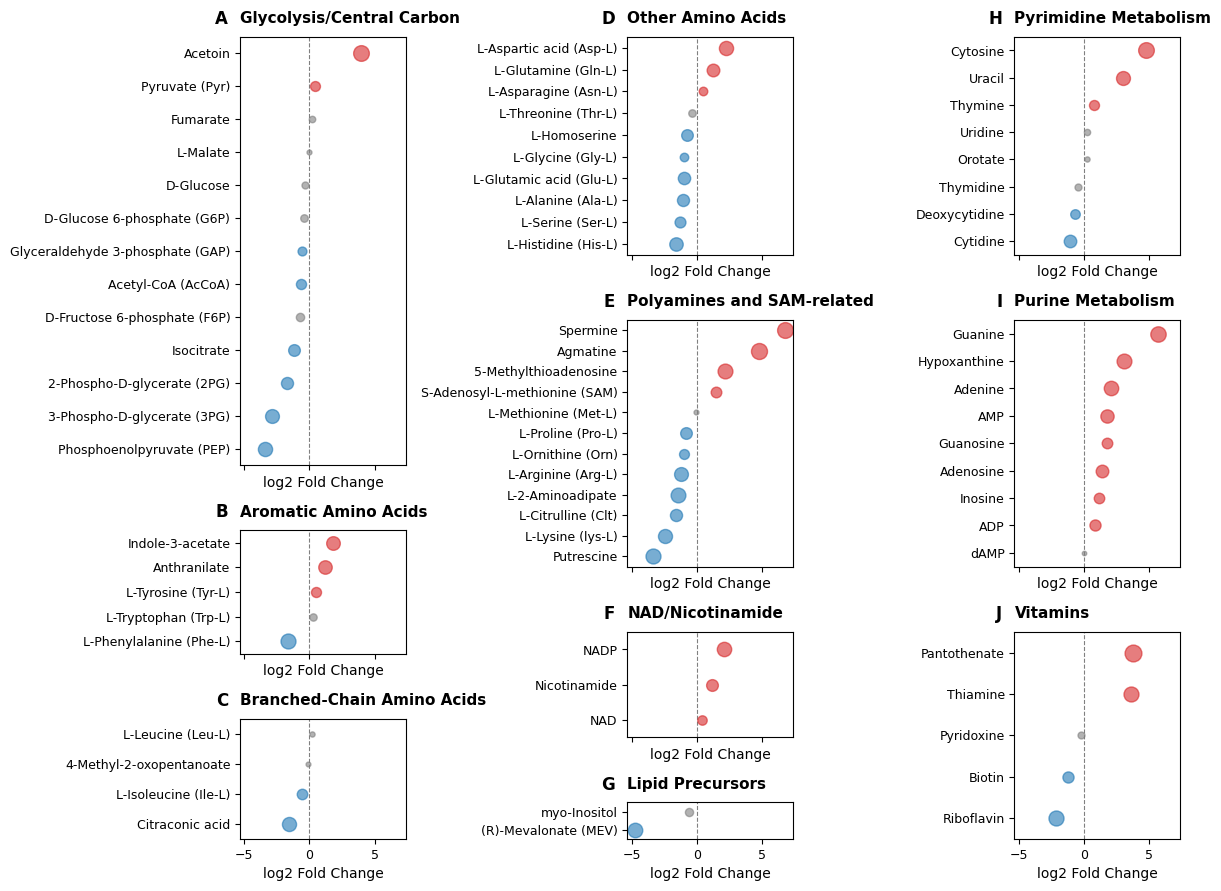

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pal = sns.color_palette("tab10")
color_map = {
    'Up': pal[3],
    'Down': pal[0],
    'NS': pal[7]
}

#pathways = limma_results_dedupe['pathway'].unique()
pathways_custom_order = ["Glycolysis/Central Carbon", "Aromatic Amino Acids", "Branched-Chain Amino Acids",
                         "Other Amino Acids", "Polyamines and SAM-related", "NAD/Nicotinamide",
                         "Lipid Precursors", "Pyrimidine Metabolism", "Purine Metabolism", "Vitamins"]

panel_configs = {chr(65+i): pathway for i, pathway in enumerate(pathways_custom_order)}

layout = [
    ['A', 'D', 'H'],
    ['A', 'E', 'I'],
    ['B', 'E', 'I'],
    ['B', 'F', 'J'],
    ['C', 'F', 'J'],
    ['C', 'G', 'J'],
]

width_ratios = [1, 1, 1]
height_ratios = [0.6, 0.4, 0.1, 0.06, 0.05, 0.1]
figsize = (12, 9)

fig, axs = plt.subplot_mosaic(layout, 
                              width_ratios=width_ratios,
                              height_ratios=height_ratios,
                              figsize=figsize,
                              sharex=True)

for panel_label, pathway in panel_configs.items():
    if panel_label not in axs:
        continue
    
    ax = axs[panel_label]
    
    plot_df = limma_results_dedupe[limma_results_dedupe['pathway'] == pathway].copy()
    plot_df['size'] = 10 + -np.log10(plot_df['adj.P.Val']) * 20
    plot_df = plot_df.sort_values("logFC")
    
    for _, row in plot_df.iterrows():
        ax.scatter(
            x=row['logFC'],
            y=row['model_name'],
            color=color_map[row['significance']],
            s=row['size'],
            alpha=0.6,
            label=row['significance']
        )
    
    n_reactions = len(plot_df['model_name'].unique())
    fixed_margin = 0.5  # Fixed margin in data units
    ax.set_ylim(-fixed_margin, n_reactions - 1 + fixed_margin)
    
    ax.axvline(0, color="grey", ls="--", zorder=0, linewidth=0.8)
    ax.set_xlabel('log2 Fold Change', fontsize=10)
    ax.set_ylabel('', fontsize=10)
    ax.set_title(pathway, fontsize=11, pad=10, fontweight='bold', loc='left')
    ax.tick_params(axis='both', labelsize=9)

plt.tight_layout()

# Add panel labels
for panel_label, config in panel_configs.items():
    if panel_label not in axs:
        continue
    ax = axs[panel_label]

    bb = ax.get_position()  # returns Bbox with x0, y0, x1, y1 in figure fraction

    # Place label at top-left of axes, with a small offset
    x_fig = bb.x0 - 0.01
    y_fig = bb.y1 + 0.01

    fig.text(
        x_fig, y_fig,
        panel_label,
        fontsize=12,
        fontweight='bold',
        va='bottom',
        ha='right',
        transform=fig.transFigure
    )
    
plt.savefig(os.path.join(outdir, 'Fig_9_metabolome_changes.png'),
            dpi=300, bbox_inches='tight')
plt.show()

# Figure 7: Network plot

The code for producing Figure 7 (interactive network plot) can be found here: https://github.com/zhanglab/pfu-bdo-networkvis

Docker image for running the visualization is available in dockerhub: jvjvjvjv/pfu-bdo-networkvis

# Figure 1 (MRA): Volcano plot

In [25]:
# Number of spectra identified in the targeted dataset
pfu_targeted_limma.shape[0]

381

In [26]:
# Number of metabolites identified in the targeted dataset
len(set([x.replace("_unlabeled", "") for x in pfu_targeted_limma.metabolite if not pd.isna(x)]))

239

In [27]:
# Total number of spectra in the untargeted dataset
pfu_untargeted_limma.shape[0]

18666

In [28]:
# Number of annotated spectra in the untargeted dataset
pfu_untargeted_limma.query("~propagated_annotation.isna() & annotation_source != 'propagated'").shape[0]

694

In [29]:
# Number of metabolites in the untargeted dataset
len(pfu_untargeted_limma.propagated_annotation.dropna().unique())

246

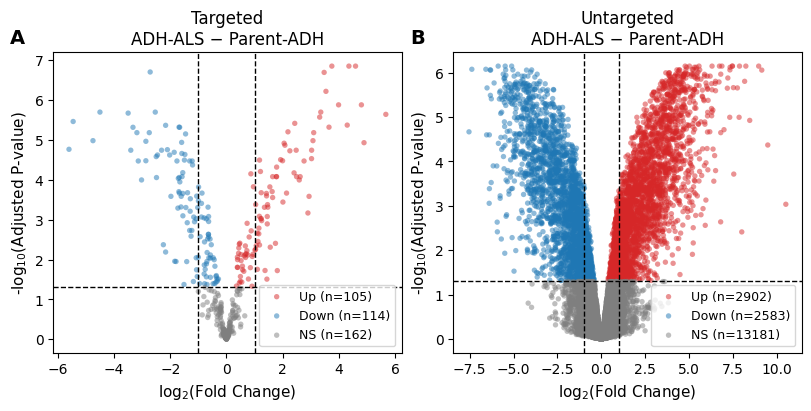

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplot_mosaic(
    [["A", "B"]],
    figsize=(8, 4),
    constrained_layout=True
)

pal = sns.color_palette("tab10")
color_map = {
    'Up': pal[3],
    'Down': pal[0],
    'NS': pal[7]
}

pval_threshold = 0.05
fc_threshold = 1

for panel_label, (ax_key, df, title) in zip(
    ["A", "B"],
    [
        ("A", pfu_targeted_limma, "Targeted"),
        ("B", pfu_untargeted_limma, "Untargeted"),
    ]
):
    ax = axes[ax_key]
    
    df = df.copy()
    df["-log10_adjP"] = -np.log10(df["adj.P.Val"])
    
    for sig, color in color_map.items():
        subset = df[df["significance"] == sig]
        n = len(subset)
        ax.scatter(
            subset["logFC"],
            subset["-log10_adjP"],
            color=color,
            s=15,
            alpha=0.5,
            edgecolors="none",
            label=f"{sig} (n={n})",
        )
    
    ax.axhline(-np.log10(pval_threshold), color="black", linestyle="--", linewidth=1)
    ax.axvline(-fc_threshold, color="black", linestyle="--", linewidth=1)
    ax.axvline(fc_threshold, color="black", linestyle="--", linewidth=1)
    
    ax.set_xlabel("log$_2$(Fold Change)", fontsize=11)
    ax.set_ylabel("-log$_{10}$(Adjusted P-value)", fontsize=11)
    
    ax.set_title(f"{title}\nADH-ALS − Parent-ADH", fontsize=12)
    
    ax.text(
        -0.08, 1.08, panel_label,
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        va="top",
        ha="right",
    )
    
    ax.legend(loc="lower right", framealpha=0.8, fontsize=9, markerscale=1)

plt.savefig(os.path.join(outdir, 'MRA_Fig_1_volcano.png'),
            dpi=300, bbox_inches='tight')
plt.show()

# Absolute quantification

In [31]:
import statsmodels.api as sm

def lm_and_predict(x, y, x_new, alpha=0.05):
    # Fit the regression
    X = sm.add_constant(x)  # adds intercept
    model = sm.OLS(y, X).fit()
    X_new = sm.add_constant(x_new, has_constant="add")
    y_pred = model.get_prediction(X_new)
    return y_pred.conf_int(alpha=alpha)

def metabolite_concentration_regression(metabolite, chemistry, mode, reference_sample, plot_group,
                                        noise_threshold=1e5, variable="peak_height", plot=False, save_plot=False):
    plot_groups = [plot_group]
    custom_order = list(itertools.chain(*[groups[x] for x in plot_groups]))
    pal = sns.color_palette("Set1")

    # 1. Predict the actual peak height in ISTD-like sample with a regression
    ref_height = np.mean(np.log10(
        binal_bf.query(
        "(metabolite == @metabolite) & "
        "(variable == @variable) & "
        "(sample_treatment == @reference_sample) & "
        "(CustomStds == True) & "
        "(chemistry == @chemistry) & "
        "(mode == @mode)"
    ).value))

    blib = blob[[reference_sample, "ISTD"]].dropna().sort_values(reference_sample)
    conf_int = lm_and_predict(blib[reference_sample], blib["ISTD"],
                                 [ref_height], alpha=0.05)[0]

    # 2. Make a regression of the MixA/MixB standard concentrations vs intensity
    df_subset = binal_bf.query(
        "(metabolite == @metabolite) & "
        "(variable == @variable) & "
        "(CustomStds == True) & "
        "(chemistry == @chemistry) & "
        "(mode == @mode) & "
        "(group.isin(@plot_groups)) & "
        "(value > @noise_threshold)"
    ).copy()

    # Parses the concentration from the Mix sample name
    df_subset["standard_conc"] = [float(x.split("-")[-1].replace("pt", ".")) for x in df_subset["sample_treatment"]]
    df_subset = df_subset.sort_values("standard_conc")
    
    # Quit early if the signal in sample is noise
    if (pd.isna(ref_height)) or (np.power(10, ref_height) < noise_threshold):
        print("Value is below noise level")
        detection_limit = df_subset["standard_conc"].iloc[0]
        return [0, detection_limit]

    # Log-scale data for linear regression
    x = np.log10(df_subset.dropna()["standard_conc"].to_numpy())
    y = np.log10(df_subset.dropna()["value"].to_numpy())
    
    if len(x) == 0:
        print("No data was queried from the table, may be an issue in your metabolite or group naming")
        return -999
    
    # fit the regression
    X = sm.add_constant(x)  # adds intercept
    model = sm.OLS(y, X).fit()
    y_pred = model.predict(X)

    # 3. Calculate the intercepts and read out actual concentrations
    intercepts = (conf_int - model.params[0])/model.params[1]
    intercepts_unlogged = np.power(10, intercepts)
    if plot:
        # 4. Plotting.
        # Un-log it for plotting, then log-scale the axes to get the pretty log axes
        x_unlogged = np.power(10, x)
        y_unlogged = np.power(10, y)
        
        y_pred_unlogged = np.power(10, y_pred)
        conf_int_unlogged = np.power(10, conf_int)
        plt.scatter(x_unlogged, y_unlogged, color="k", label="Intensity in standards", s=40, edgecolor="white")
        #sns.scatterplot(x=x_unlogged, y=y_unlogged, color="k", label="Intensity in standards")
        sns.lineplot(x=x_unlogged, y=y_pred_unlogged, color=pal[1], label="Regression on standards")

        plt.axhline(conf_int_unlogged[0], color=pal[0], alpha=0.2, label=f"Adjusted intensity for ISTD")
        plt.axhline(conf_int_unlogged[1], color=pal[0], alpha=0.2)
        plt.axhspan(conf_int_unlogged[0], conf_int_unlogged[1], color=pal[0], alpha=0.2)
        plt.axvline(intercepts_unlogged[0], color=pal[0], ls="--", alpha=0.2, label=f"Predicted concentration in {reference_sample}")
        plt.axvline(intercepts_unlogged[1], color=pal[0], ls="--", alpha=0.4)
        plt.axvspan(intercepts_unlogged[0], intercepts_unlogged[1], color=pal[0], alpha=0.2)

        plt.legend()
        plt.yscale("log")
        plt.xscale("log")
        plt.grid(True)
        plt.title(f"{reference_sample} {metabolite} {chemistry} {mode}")
        plt.xlabel(f"Standard concentration ({plot_groups[0]})")
        plt.ylabel("Peak Height")
        if save_plot:
            plt.savefig(f"/work/pi_yingzhang_uri_edu/jvailionis/figs/2025-09-26_metabolomics/regression_concentration_{metabolite}_{chemistry}_{mode}_{reference_sample}_{plot_group}_concentrations.png",
                        dpi=300, bbox_inches="tight")
        plt.show()
    return intercepts_unlogged

def metabolite_concentration_bounds(metabolite, chemistry, mode, reference_sample,
                                    noise_threshold=1e5, variable="peak_height", ignore_noise_for_stds=False):
    # 1. Predict the actual peak height in ISTD-like sample with a regression
    ref_height = np.mean(np.log10(
        binal_bf.query(
        "(metabolite == @metabolite) & "
        "(variable == @variable) & "
        "(sample_treatment == @reference_sample) & "
        "(CustomStds == True) & "
        "(chemistry == @chemistry) & "
        "(mode == @mode)"
    ).value))

    blib = blob[[reference_sample, "ISTD"]].dropna().sort_values(reference_sample)
    conf_int = lm_and_predict(blib[reference_sample], blib["ISTD"],
                                 [ref_height], alpha=0.05)[0]

    # 2. Extract the low and high bounds, depending on whether they are above the noise
    mixes = [row["primary mix"], f'{row["primary mix"]}-100ugml']
    if ignore_noise_for_stds:
        std_noise_threshold = 0
    else:
        std_noise_threshold = noise_threshold

    df_subset = binal_bf.query(
        "(metabolite == @metabolite) & "
        "(variable == @variable) & "
        "(CustomStds == True) & "
        "(chemistry == @chemistry) & "
        "(mode == @mode) & "
        "(sample_treatment.isin(@mixes)) & "
        "(value > @std_noise_threshold)"
    )[["sample_treatment", "value"]].groupby("sample_treatment").apply(lambda g: np.mean(np.log10(g)),
                                                                       include_groups=False)
    
    # If sample is noise, treat as 0
    if (pd.isna(ref_height)) or (np.power(10, ref_height) < noise_threshold):
        ref_height = 0
        conf_int = [0, 0]
    
    # If neither standards had a peak
    if len(df_subset) == 0:
        print("Sample not picked up in standards, cannot assign concentration")
        return [np.nan, np.nan]
    # If only one of the standards had a peak
    elif len(df_subset) == 1:
        out_vals = []
        if df_subset.index[0].endswith("100ugml"):
            conc = 100
        else:
            conc = 10
        for n in conf_int:
            # If it's within an order of magnitude, infer a concentration, otherwise it's a broad limit
            if n > df_subset.values[0]+1:
                out_vals.append(np.inf)
            elif n < df_subset.values[0]-1:
                out_vals.append(0)
            else:
                print(f"{metabolite} value {n} is within one order of magnitude of the standard flux, inferring conc.")
                out_vals.append(conc*(n/df_subset.values[0]))
        if out_vals == [0, 0]:
            return [0, conc]
        elif out_vals == [np.inf, np.inf]:
            return [conc, np.inf]
        else:
            return out_vals
    # If both standards had a peak, interpolate the values                        
    elif len(df_subset == 2):
        conc = 10
        y_points = df_subset.values
        x_points = [10, 100]
        out_vals = list(np.interp(conf_int, y_points, x_points, left=0, right=np.inf))
        if out_vals[1] == np.inf:
            out_vals[1] = 100*(conf_int[1]/y_points[1])
        if out_vals == [0, 0]:
            return [0, 10]
        elif out_vals == [np.inf, np.inf]:
            return [100, np.inf]
        else:
            return out_vals

In [32]:
outdir = "./output"

In [33]:
final_df = pd.read_table("./data/metabolomics/2026-04-01_targeted_df_long.tsv", sep="\t", index_col=0)

# This has the notes I took after manually going through the peaks for the 21 probed metabolites
metab_annotation_path = "./data/metabolomics/2026-07-16_metabolomics_annotations.tsv"
metab_annotation_df = pd.read_table(metab_annotation_path)

In [34]:
# Define groups used to subset the plots, and define the order of plotting samples
groups = {
    "Ctrl": ["ExCtrl", "ISTD"],
    "Abes": ["Abes-cond-media", "Abes-MACB1034-100A", "Abes-RKCB94-100A"],
    "Pfu": ["Pfu-cond-media", "Pfu-COM1", "Pfu-MW698-BDO"],
    "Standards": [
        "AMP", "AMP-100ugml", "ADP", "ADP-100ugml", "ATP", "ATP-100ugml",
        "NAD", "NAD-100ugml", "NADH", "NADH-100ugml", "NADP", "NADP-100ugml", "NADPH", "NADPH-100ugml",
        "CoenzymeA", "CoenzymeA-100ugml", "Glucose", "Glucose-100ugml",
        "Ribose-5-phosphate", "Ribose-5-phosphate-100ugml", "Ribulose-1-5-bisphosphate", "Ribulose-1-5-bisphosphate-100ugml",
    ],
    "MixA": [
        "MixA-pt01", "MixA-pt025", "MixA-pt05", "MixA-pt075", "MixA-pt1", "MixA-pt25", "MixA-pt5", "MixA-pt75", 
        "MixA-1", "MixA-2pt5", "MixA-5", "MixA-7pt5", "MixA-10", "MixA-25", "MixA-50", "MixA-75", "MixA-100"
    ],
    "MixB": [
        "MixB-pt01", "MixB-pt025", "MixB-pt05", "MixB-pt075", "MixB-pt1", "MixB-pt25", "MixB-pt5", "MixB-pt75", 
        "MixB-1", "MixB-2pt5", "MixB-5", "MixB-7pt5", "MixB-10", "MixB-25", "MixB-50", "MixB-75", "MixB-100",
    ]
}

# Function to determine the group of a sample treatment
def find_group(sample_treatment):
    for group, treatments in groups.items():
        if sample_treatment in treatments:
            return group
    return "Unknown"  # Or any default value you want to assign

final_df["group"] = final_df["sample_treatment"].apply(find_group)

In [35]:
# I had to de-replicate it here after they added the re-analyzed samples
binal_bf = final_df.groupby(["sample", "CustomStds", "chemistry", "mode", "database", "variable", "metabolite", "adduct"]).last().reset_index()

In [36]:
# Grab the log10 peak heights for the isotopically labeled standards in HILIC POS
# HILIC POS was the only chemistry/mode to have essentially all of the standards represented (48/50)
variable = "peak_height"
plot_groups = ["Ctrl", "Abes", "Pfu"]
chemistry = "HILIC"
mode = "NEG"
custom_order = list(itertools.chain(*[groups[x] for x in plot_groups]))
#subset1 = final_df[["13C6" in x for x in final_df.metabolite]]
subset2 = final_df.copy().query(
    "(variable == @variable) & "
    "(chemistry == @chemistry) & "
    "(mode == @mode) & "
    "(group.isin(@plot_groups))"
)
subset2["metabolduct"] = subset2["metabolite"] +"_["+ subset2["adduct"] + "]"
subset2["value"] = np.log10(subset2["value"])
bleb = (
    subset2[["sample_treatment", "metabolduct", "value"]]
    .groupby(["sample_treatment", "metabolduct"])
    .mean().reset_index()
    .pivot(columns="sample_treatment", index="metabolduct", values="value")
)
blob = bleb[[("15N" in ind) or ("13C" in ind) or ("ABMBA" in ind) for ind in bleb.index]]

In [37]:
data = []
for _, row in metab_annotation_df.iterrows():
    print(row["Compound"])
    if row["primary mix"] == "ISTD":
        continue
    elif row["primary mix"] in ["Mix A", "Mix B"]:
        for sample_treatment in ["Pfu-COM1", "Pfu-MW698-BDO"]:
            info = [row["Compound"], row["best chemistry"], row["best mode"],
                    sample_treatment, row["primary mix"].replace(" ", "")]
            val = metabolite_concentration_regression(*info, noise_threshold=float(row["background noise level"]))
            data.append([*info, *val])
    else:
        for sample_treatment in ["Pfu-COM1", "Pfu-MW698-BDO"]:
            info = [row["Compound"], row["best chemistry"], row["best mode"],
                    sample_treatment]
            val = metabolite_concentration_bounds(
                *info, noise_threshold=float(row["background noise level"]),
                variable="peak_height", ignore_noise_for_stds=True)
            data.append([*info, "Standards", *val])
        
df_real_concs = pd.DataFrame(data)
df_real_concs.columns = ["metabolite", "chemistry", "mode", "sample_treatment",
                         "primary_mix", "lower_bound_ugml", "upper_bound_ugml"]

Acetyl-CoA
Value is below noise level
Value is below noise level
Acetolactate
Value is below noise level
Value is below noise level
Acetoacetate
Value is below noise level
Value is below noise level
Acetoin
Value is below noise level
Glucose-6-phosphate (13C6)
Glucose-6-phosphate
Fructose-6-phosphate (13C6)
Fructose-6-phosphate
Fructose-1_6-bisphosphate_13C6
Fructose-1_6-bisphosphate
Value is below noise level
Value is below noise level
Glyceraldehyde-3-phosphate
Value is below noise level
Value is below noise level
3-phosphoglycerate
Phosphoenolpyruvate
Pyruvate_13C6
Pyruvate
CoA
ATP
ADP
AMP
NADPH
NADP
NADH
NAD
Glucose_13C6
Glucose
Sample not picked up in standards, cannot assign concentration
Sample not picked up in standards, cannot assign concentration
Ribulose-1-5-bisphosphate
Ribose-5-phosphate


# Table 1 (MRA): Absolute quantification values

In [38]:
# Converting to mM
mw_map = {
    "Acetyl-CoA": 809.57,
    "Acetolactate": 132.11,
    "Acetoacetate": 101.08,
    "Acetoin": 88.11,
    "Glucose-6-phosphate": 260.14,
    "Fructose-1_6-bisphosphate": 340.12,
    "Fructose-6-phosphate": 260.14,
    "Glyceraldehyde-3-phosphate": 170.06,
    "3-phosphoglycerate": 186.06,
    "Phosphoenolpyruvate": 168.04,
    "CoA": 767.5,
    "ATP": 507.18,
    "ADP": 427.2,
    "AMP": 347.22,
    "NADPH": 745.4,
    "NADP": 743.4,
    "NADH": 665.4,
    "NAD": 663.4,
    "Glucose": 180.16,
    "Ribulose-1-5-bisphosphate": 310.09,
    "Ribose-5-phosphate": 230.11
}
df_real_concs["mw_gmol"] = [mw_map[m] for m in df_real_concs["metabolite"]]
df_real_concs["lower_bound_mM"] = df_real_concs["lower_bound_ugml"]/df_real_concs["mw_gmol"]
df_real_concs["upper_bound_mM"] = df_real_concs["upper_bound_ugml"]/df_real_concs["mw_gmol"]

df_real_concs["lower_bound_uM"] = df_real_concs["lower_bound_mM"]*1000
df_real_concs["upper_bound_uM"] = df_real_concs["upper_bound_mM"]*1000

In [39]:
# Verify that chemistry and mode are consistent per metabolite
assert df_real_concs.groupby('metabolite')['chemistry'].nunique().max() == 1, \
    "Chemistry is not consistent across samples for some metabolites"
assert df_real_concs.groupby('metabolite')['mode'].nunique().max() == 1, \
    "Mode is not consistent across samples for some metabolites"

# Create the formatted concentration string
def format_concentration(row):
    if row['lower_bound_uM'] == 0:
        return f"<{row['upper_bound_uM']:.1f}"
    else:
        return f"{row['lower_bound_uM']:.1f}–{row['upper_bound_uM']:.1f}"

df_real_concs['formatted'] = df_real_concs.apply(format_concentration, axis=1)

# Pivot to get sample_treatment as columns
manuscript_df = df_real_concs.pivot_table(
    index='metabolite',
    columns='sample_treatment',
    values='formatted',
    aggfunc='first'
).reset_index()

# Rename columns to match manuscript style
manuscript_df = manuscript_df.rename(columns={
    'metabolite': 'Metabolite',
    'Pfu-COM1': 'Parent-ADH',
    'Pfu-MW698-BDO': 'ADH-ALS'
})

# Add chemistry and mode columns
chem_mode = df_real_concs.groupby('metabolite')[['chemistry', 'mode']].first().reset_index()
manuscript_df = manuscript_df.merge(
    chem_mode,
    left_on='Metabolite',
    right_on='metabolite'
).drop(columns='metabolite')

# Reorder columns
manuscript_df = manuscript_df[['Metabolite', 'chemistry', 'mode', 'Parent-ADH', 'ADH-ALS']]

In [40]:
row_order = [
    "Glucose-6-phosphate", "Fructose-6-phosphate", "Fructose-1_6-bisphosphate",
    "Glyceraldehyde-3-phosphate", "3-phosphoglycerate", "Phosphoenolpyruvate",
    "Ribose-5-phosphate", "Ribulose-1-5-bisphosphate", "CoA", "Acetyl-CoA",
    "Acetolactate", "Acetoin", "AMP", "ADP", "ATP", "NAD", "NADH", "NADP", "NADPH"  
]

In [41]:
manuscript_df = manuscript_df.set_index("Metabolite").loc[row_order].rename(
    index={"Fructose-1_6-bisphosphate": "Fructose-1,6-bisphosphate",
           "Ribulose-1-5-bisphosphate": "Ribulose-1,5-bisphosphate"},
    columns={"chemistry": "Chromatography", "mode": "Ionization mode"}
)
manuscript_df["Ionization mode"] = manuscript_df["Ionization mode"].replace("NEG", "negative").replace("POS", "positive")

In [42]:
manuscript_df

,Chromatography,Ionization mode,Parent-ADH,ADH-ALS
Metabolite,,,,
Glucose-6-phosphate,HILIC,negative,42.1–56.5,40.5–55.3
Fructose-6-phosphate,HILIC,negative,76.9–93.4,61.9–76.7
"Fructose-1,6-bisphosphate",HILIC,negative,<14.7,<14.7
Glyceraldehyde-3-phosphate,HILIC,negative,<147.0,<147.0
3-phosphoglycerate,HILIC,negative,74.3–100.6,24.5–40.3
Phosphoenolpyruvate,HILIC,negative,66.9–88.6,19.1–29.0
Ribose-5-phosphate,HILIC,negative,<43.5,<43.5
"Ribulose-1,5-bisphosphate",HILIC,positive,<32.2,<32.2
CoA,HILIC,positive,<13.0,<13.0


In [43]:
manuscript_df.to_csv(os.path.join(outdir, "Table_1_MRA.tsv"), sep="\t")

# Figure S5 - Peak height correction models

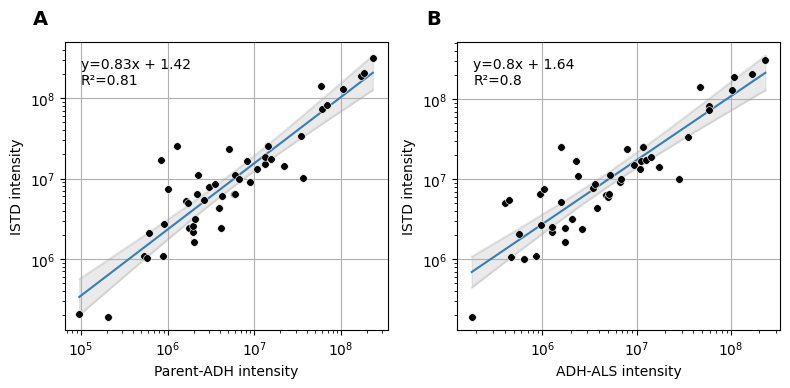

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

pal = sns.color_palette("Set1")

groups = [("Pfu-COM1", "ISTD"), ("Pfu-MW698-BDO", "ISTD")]
panel_labels = ["A", "B"]

for idx, (group1, group2) in enumerate(groups):
    ax = axes[idx]
    
    blib_sub = blob[[group1, group2]].dropna().sort_values(group1)
    
    # Log-scale data for linear regression
    x = blib_sub[group1]
    y = blib_sub[group2]
    
    # Fit the regression
    X = sm.add_constant(x)
    model = sm.OLS(y, X).fit()
    y_pred = model.predict(X)
    conf_int = model.get_prediction(X).conf_int(alpha=0.05)
    
    # Un-log for plotting
    x_unlogged = np.power(10, x)
    y_unlogged = np.power(10, y)
    y_pred_unlogged = np.power(10, y_pred)
    conf_int_unlogged = np.power(10, conf_int)
    
    # Plot
    sns.scatterplot(x=x_unlogged, y=y_unlogged, color="k", zorder=100, ax=ax, s=30)
    sns.lineplot(x=x_unlogged, y=y_pred_unlogged, color=pal[1], zorder=99, ax=ax)
    sns.lineplot(x=x_unlogged, y=conf_int_unlogged[:, 0], color=pal[-1], alpha=0.2, ax=ax)
    sns.lineplot(x=x_unlogged, y=conf_int_unlogged[:, 1], color=pal[-1], alpha=0.2, ax=ax)
    ax.fill_between(x_unlogged, conf_int_unlogged[:, 0], conf_int_unlogged[:, 1],
                    alpha=0.2, color=pal[-1])
    
    # Annotation
    label_text = (f"y={round(model.params.loc[group1], 2)}x + {round(model.params.loc['const'], 2)}"
                  f"\nR²={round(model.rsquared, 2)}")
    ax.text(0.05, 0.95, label_text, transform=ax.transAxes,
            fontsize=10, va='top', ha='left')
    
    # Formatting
    ax.set_yscale("log")
    ax.set_xscale("log")
    ax.grid(True)

    sample_name_map = {
        "Pfu-COM1": "Parent-ADH",
        "Pfu-MW698-BDO": "ADH-ALS"
    }
    ax.set_xlabel(f"{sample_name_map[group1]} intensity")
    ax.set_ylabel(f"{group2} intensity")
    
    # Panel label
    ax.text(-0.05, 1.05, panel_labels[idx], transform=ax.transAxes,
            fontsize=14, fontweight='bold', va='bottom', ha='right')

plt.tight_layout()
plt.savefig(os.path.join(outdir, 'Fig_S5_matrix_effect.png'),
            dpi=300, bbox_inches='tight')
plt.show()